# 14 – Release Date Visualization

This notebook explores patterns across movie release dates from `data/features/09_popularity_features.csv`:
1. **Movie Count by Release Decade** (Bar Chart)
2. **Average Target Log Popularity by Release Decade** (Bar Chart)
3. **Movie Counts by Release Decade and Month** (Heatmap)

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# Set project root path (2 levels above notebooks/visualization/)
PROJECT_ROOT = Path.cwd().parent.parent
INPUT_PATH = PROJECT_ROOT / "data" / "features" / "09_popularity_features.csv"

# Load dataset
df = pd.read_csv(INPUT_PATH)
print(f"Dataset shape: {df.shape}")

Dataset shape: (45430, 34)


## 1. Movie Count by Release Decade

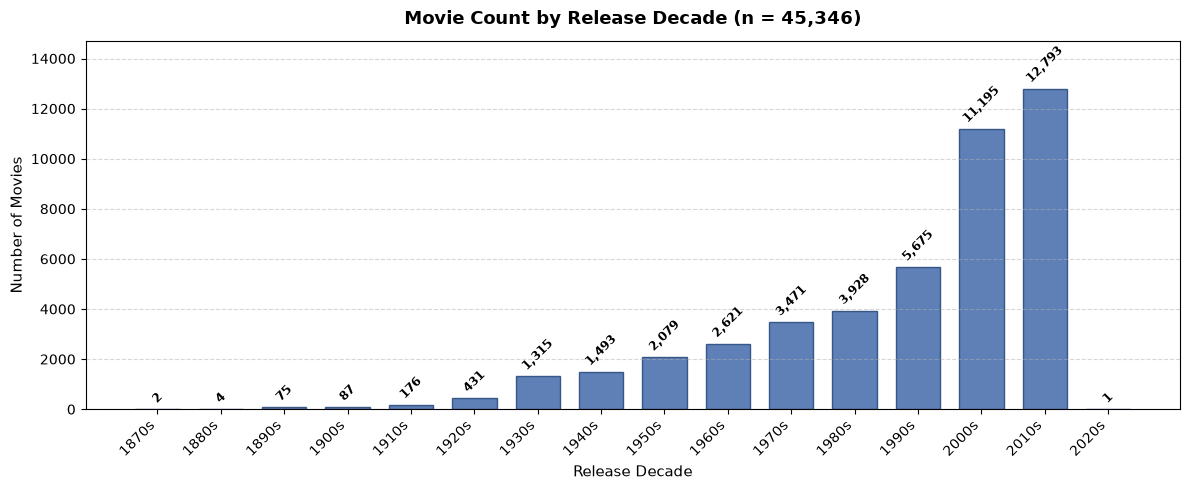

In [5]:
# Compute count per decade
decade_counts = df["release_decade"].dropna().astype(int).value_counts().sort_index()
decade_labels = [f"{d}s" for d in decade_counts.index]

plt.figure(figsize=(12, 5))
bars = plt.bar(decade_labels, decade_counts.values, color="#4C72B0", edgecolor="#2B4C7E", width=0.7, alpha=0.9)

# Annotate bar values
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, height + 150, f"{int(height):,}",
             ha="center", va="bottom", fontsize=8.5, fontweight="semibold", rotation=45)

plt.title(f"Movie Count by Release Decade (n = {decade_counts.sum():,})", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Release Decade", fontsize=11)
plt.ylabel("Number of Movies", fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.ylim(0, max(decade_counts.values) * 1.15)
plt.tight_layout()
plt.show()

## 2. Average Target Log Popularity by Release Decade

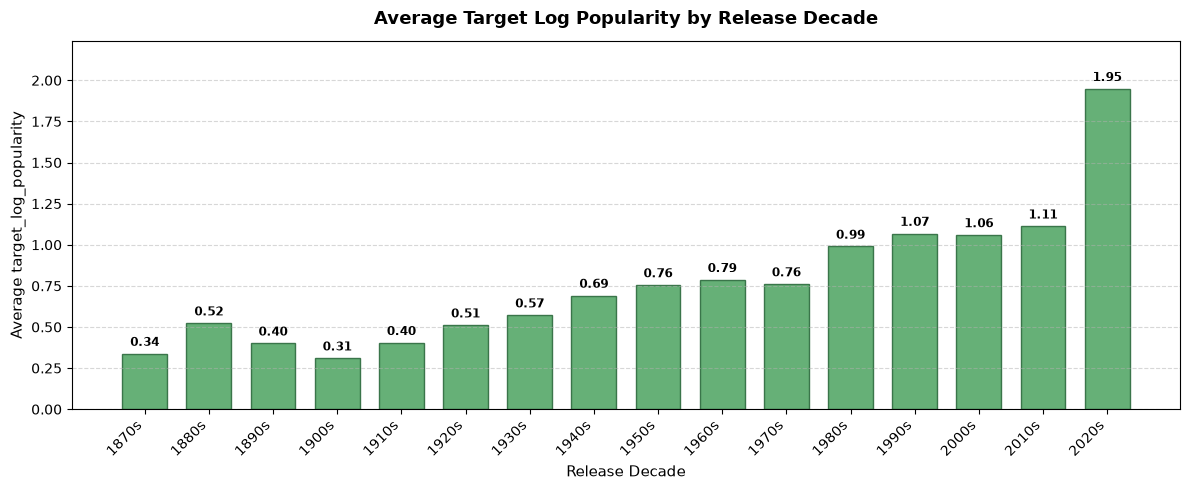

In [6]:
# Compute mean popularity per decade
avg_pop = df.groupby("release_decade")["target_log_popularity"].mean()

plt.figure(figsize=(12, 5))
bars = plt.bar([f"{int(d)}s" for d in avg_pop.index], avg_pop.values,
               color="#55A868", edgecolor="#2D6A3E", width=0.7, alpha=0.9)

# Annotate mean values
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, height + 0.03, f"{height:.2f}",
             ha="center", va="bottom", fontsize=8.5, fontweight="semibold")

plt.title("Average Target Log Popularity by Release Decade", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Release Decade", fontsize=11)
plt.ylabel("Average target_log_popularity", fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.ylim(0, max(avg_pop.values) * 1.15)
plt.tight_layout()
plt.show()

## 3. Heatmap of Movie Counts by Release Decade and Month

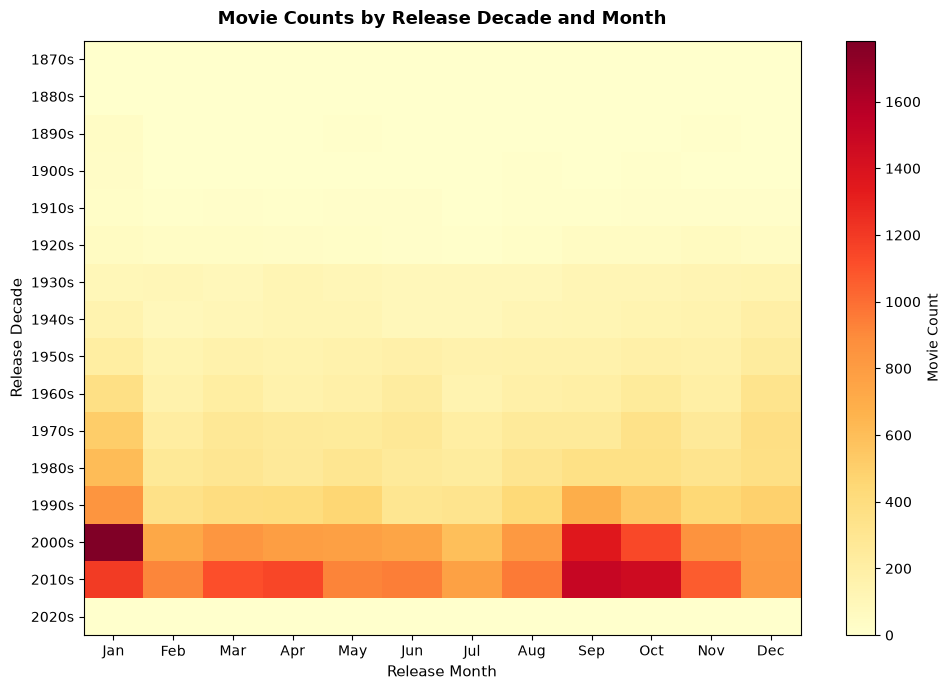

In [7]:
# Cross-tabulate decade and month counts
heatmap_data = pd.crosstab(
    df["release_decade"].dropna().astype(int),
    df["release_month"].dropna().astype(int)
)

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
decades = [f"{d}s" for d in heatmap_data.index]

plt.figure(figsize=(10, 7))
plt.imshow(heatmap_data.values, cmap="YlOrRd", aspect="auto")
plt.colorbar(label="Movie Count")

plt.xticks(range(12), months, fontsize=10)
plt.yticks(range(len(decades)), decades, fontsize=10)
plt.xlabel("Release Month", fontsize=11)
plt.ylabel("Release Decade", fontsize=11)
plt.title("Movie Counts by Release Decade and Month", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

## 4. Key Takeaways

1. **Volume Growth**: Production surged dramatically post-1980, with the 2000s and 2010s comprising over 52% of the dataset.
2. **Popularity Trend**: Average `target_log_popularity` steadily rises over time—from ~0.3–0.5 in early cinema (1870–1920) to ~1.0–1.1 in recent decades (1980–2010), reflecting user rating activity on modern platforms.
3. **Seasonal Concentration**: In modern decades, releases cluster heavily around January (festival & archival entries), September (fall film festivals), and October (seasonal & awards releases).